# 02 — Entorno: densidad del aire, parques y ambiente ofensivo

El dataset solo trae `altitude_category` (3 niveles); **no trae estadio ni altitud en metros**. En este notebook:
1. Medimos la **densidad relativa del aire por juego** usando el arrastre (la pelota pierde menos velocidad en aire
   delgado).
2. **Reconstruimos el parque** de cada juego: en la parte alta de la entrada lanza el equipo local, así que agrupando
   pitchers que lanzan juntos recuperamos equipos → equipo local → parque (`park_id`).
3. Buscamos a **Harp Helú** entre los parques de altitud extrema.
4. Comparamos el ambiente ofensivo (carreras, HR, BABIP, K%, BB%) por altitud.

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.data_prep import build_dataset, park_summary, PROCESSED_PATH, ALTITUDE_ORDER
from src.viz import set_style, savefig, ALT_COLORS, ALT_LABELS, CAT, MUTED, INK2
set_style(); pd.set_option("display.width", 200)
df = pd.read_parquet(PROCESSED_PATH) if PROCESSED_PATH.exists() else build_dataset(save=True)[0]
games = df.drop_duplicates("game_anon_id").set_index("game_anon_id")

## 1. Densidad del aire por juego
El arrastre es proporcional a la densidad del aire. Usamos la **mediana por juego del % de velocidad que pierde el
four-seam** entre la mano y el plato y la dividimos entre la mediana de los juegos "No Altitude".
`air_density_ratio = 0.82` ≈ "el aire tiene 82% de la densidad de un parque sin altitud".

Referencia física: Coors Field ≈ 0.82 de nivel del mar; CDMX (2,240 m) ≈ 0.76–0.80 según la temperatura.
Nuestra referencia "No Altitude" no es exactamente nivel del mar, así que los ratios son relativos a la liga.

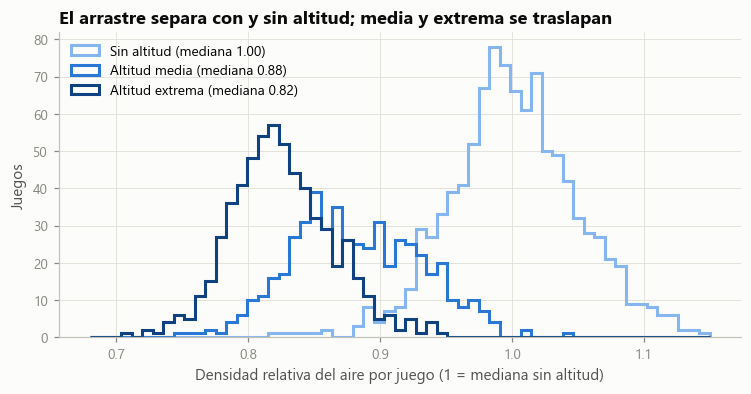

,count,mean,std,min,5%,50%,95%,max
altitude_category,,,,,,,,
No Altitude,1002.0,1.002,0.050,0.816,0.927,1.000,1.085,1.202
Medium Altitude,508.0,0.882,0.048,0.747,0.808,0.878,0.961,1.041
Extreme Altitude,601.0,0.825,0.038,0.710,0.768,0.821,0.892,0.945


In [2]:
fig, ax = plt.subplots(figsize=(8, 3.6))
bins = np.linspace(0.68, 1.15, 60)
for cat in ALTITUDE_ORDER:
    v = games.loc[games.altitude_category == cat, "air_density_ratio"].dropna()
    ax.hist(v, bins=bins, color=ALT_COLORS[cat], histtype="step", linewidth=2,
            label=f"{ALT_LABELS[cat]} (mediana {v.median():.2f})")
ax.set_xlabel("Densidad relativa del aire por juego (1 = mediana sin altitud)"); ax.set_ylabel("Juegos")
ax.set_title("El arrastre separa con y sin altitud; media y extrema se traslapan")
ax.legend(loc="upper left")
savefig(fig, "02_densidad_por_juego"); plt.show()

dens = games.groupby("altitude_category", observed=True).air_density_ratio.describe(percentiles=[.05, .5, .95]).round(3)
assert dens.loc["Extreme Altitude", "50%"] < dens.loc["Medium Altitude", "50%"] < dens.loc["No Altitude", "50%"]
dens

### ¿Cambia por temporada o por mes?
La densidad también depende de la temperatura (aire caliente = menos denso). Si 2026 es temporada parcial, puede
estar sesgada hacia meses más frescos. También puede haber cambios de calibración.

In [3]:
# no hay fecha: usamos el orden del juego dentro de la temporada
games["season_part"] = games.groupby("year").cumcount() / games.groupby("year").year.transform("size")
games["tercio"] = pd.cut(games.season_part, [0, 1/3, 2/3, 1.0001], labels=["1er tercio", "2º tercio", "3er tercio"], right=False)
pd.pivot_table(games, index=["altitude_category", "year"], columns="tercio", values="air_density_ratio",
               aggfunc="median", observed=True).round(3)

tercio                  1er tercio  2º tercio  3er tercio
altitude_category year                                   
No Altitude       2024       0.978      0.983       0.995
                  2025       1.001      1.002       1.003
                  2026       1.016      1.033       1.026
Medium Altitude   2024       0.852      0.866       0.882
                  2025       0.865      0.855       0.877
                  2026       0.933      0.923       0.922
Extreme Altitude  2024       0.809      0.818       0.833
                  2025       0.813      0.816       0.828
                  2026       0.837      0.839       0.844

*Nota: el dataset no trae fecha; el "tercio" asume que los juegos vienen en orden cronológico dentro de la temporada.*

## 2. Reconstrucción de parques (`park_id`)
Ver `add_park_ids` en `src/data_prep.py`. Validaciones:
- **Pureza del lado local**: % de pitchers de la parte alta que pertenecen al equipo local asignado.
- **Pureza de altitud**: todos los juegos de local de un equipo deberían caer en la misma categoría de altitud.
  Esta es una validación independiente, porque la altitud no se usa para construir los equipos.

In [4]:
ps = park_summary(df)
print(f"Juegos con parque asignado: {games.park_id.notna().mean():.1%} | parques: {len(ps)}")
print(f"Pureza de altitud ponderada por juegos: {(ps.altitude_purity * ps.games).sum() / ps.games.sum():.3f}")
ps.round(3)

Juegos con parque asignado: 99.3% | parques: 23
Pureza de altitud ponderada por juegos: 0.965


,games,seasons,air_density_median,air_density_se,altitude_category,altitude_purity
park_id,,,,,,
PK20,14,2025,0.775,0.009,Extreme Altitude,1.000
PK08,128,"2024,2025,2026",0.806,0.002,Extreme Altitude,1.000
PK07,116,"2024,2025,2026",0.808,0.002,Extreme Altitude,1.000
PK04,114,"2024,2025,2026",0.824,0.003,Extreme Altitude,1.000
PK03,110,"2024,2025,2026",0.835,0.004,Extreme Altitude,1.000
PK05,109,"2024,2025,2026",0.846,0.004,Medium Altitude,0.991
PK16,41,2024,0.857,0.004,Extreme Altitude,1.000
PK15,105,"2024,2025,2026",0.858,0.003,Medium Altitude,1.000
PK18,58,"2025,2026",0.873,0.005,Extreme Altitude,1.000


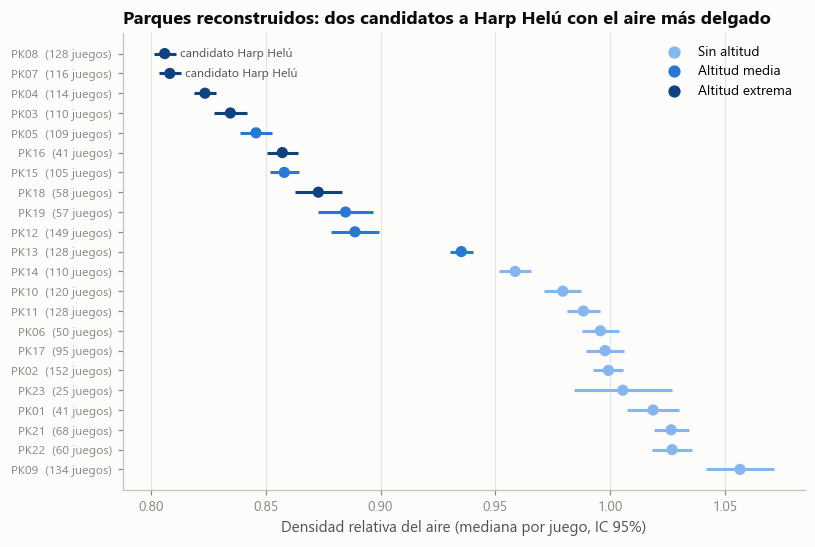

Candidatos a Harp Helú (3 temporadas, altitud extrema, aire más delgado): ['PK08', 'PK07']


In [5]:
fig, ax = plt.subplots(figsize=(8, 5.4))
p = ps[ps.games >= 20].iloc[::-1]
y = np.arange(len(p))
ax.hlines(y, p.air_density_median - 1.96 * p.air_density_se, p.air_density_median + 1.96 * p.air_density_se,
          color=[ALT_COLORS[a] for a in p.altitude_category], lw=2, linestyles="solid")
ax.scatter(p.air_density_median, y, s=40, color=[ALT_COLORS[a] for a in p.altitude_category], zorder=3)
ax.set_yticks(y); ax.set_yticklabels([f"{i}  ({n} juegos)" for i, n in zip(p.index, p.games)], fontsize=8)
ax.set_xlabel("Densidad relativa del aire (mediana por juego, IC 95%)"); ax.grid(axis="y", visible=False)
ax.set_title("Parques reconstruidos: dos candidatos a Harp Helú con el aire más delgado")
for cat in ALTITUDE_ORDER:
    ax.scatter([], [], color=ALT_COLORS[cat], label=ALT_LABELS[cat])
ax.legend(loc="upper right")
cands = ps[(ps.altitude_category == "Extreme Altitude") & (ps.games >= 100)].head(2).index.tolist()
for c in cands:
    yy = list(p.index).index(c)
    ax.annotate("candidato Harp Helú", (p.loc[c, "air_density_median"], yy), xytext=(10, 0),
                textcoords="offset points", va="center", fontsize=8, color=INK2)
savefig(fig, "02_parques_reconstruidos"); plt.show()
print("Candidatos a Harp Helú (3 temporadas, altitud extrema, aire más delgado):", cands)

**Lectura:** dentro de "Extreme Altitude" hay ~4–5 parques con densidades distintas (0.81 a 0.87). Agrupar todo
"Extreme" como si fuera CDMX **diluye** el efecto de Harp Helú. Los dos parques más delgados (≈0.81) son los
candidatos; por arrastre no se distinguen entre sí (≈100 m de altitud de diferencia ≈ 1% de densidad, del orden del
efecto de la temperatura). **Hay que confirmar con ISAC cuál es Harp Helú.**

`park_id` y `air_density_ratio` son mejores features de ambiente que las 3 categorías.

## 3. Implicación física: altitud equivalente
Con atmósfera estándar, ρ/ρ₀ ≈ exp(−h / 8,500 m). Un ratio de 0.81 respecto a la referencia implica
≈ 1,800 m **por encima** del parque "No Altitude" típico (que tampoco está a nivel del mar). Es una cuenta gruesa:
la temperatura y la humedad también mueven la densidad.

In [6]:
(-8500 * np.log(ps[ps.games >= 100].air_density_median)).round(0).rename("metros sobre la referencia (aprox.)").to_frame()

,metros sobre la referencia (aprox.)
park_id,
PK08,1834.0
PK07,1810.0
PK04,1651.0
PK03,1537.0
PK05,1424.0
PK15,1301.0
PK12,1001.0
PK13,570.0
PK14,359.0


## 4. Ambiente ofensivo por altitud
Si el aire delgado ayuda al bateador, debería verse en carreras, HR y BABIP. Es un dato **descriptivo**, porque los
equipos de cada ambiente también son distintos.

In [7]:
bip = df[df.in_play & df.hit_type.notna() & df.hit_type.ne("Bunt")]
pa_last = df[df.pa_terminal]
env = pd.DataFrame({
    "carreras/juego (ambos equipos)": df.groupby("altitude_category", observed=True).RunsScored.sum()
        / df.groupby("altitude_category", observed=True).game_anon_id.nunique(),
    "HR / batazo": bip.groupby("altitude_category", observed=True).home_run.mean(),
    "HR / fly ball": bip[bip.hit_type == "FlyBall"].groupby("altitude_category", observed=True).home_run.mean(),
    "BABIP (sin HR)": bip[bip.home_run == 0].groupby("altitude_category", observed=True).is_hit.mean(),
    "K%": pa_last.groupby("altitude_category", observed=True).strikeout.mean(),
    "BB%": pa_last.groupby("altitude_category", observed=True).base_on_balls.mean(),
    "Whiff / swing": df[df.swing].groupby("altitude_category", observed=True).whiff.mean(),
    "Distancia FB (pies)": bip[bip.hit_type == "FlyBall"].groupby("altitude_category", observed=True).Distance.median(),
    "Exit velo (mph)": bip.groupby("altitude_category", observed=True).ExitSpeed.mean(),
})
env.T.round(3)

altitude_category,No Altitude,Medium Altitude,Extreme Altitude
carreras/juego (ambos equipos),9.049801,12.520629,13.662252
HR / batazo,0.039766,0.045654,0.044617
HR / fly ball,0.12395,0.158808,0.162971
BABIP (sin HR),0.317466,0.363373,0.369058
K%,0.202331,0.178514,0.167033
BB%,0.093361,0.09613,0.09978
Whiff / swing,0.249028,0.241516,0.232338
Distancia FB (pies),294.6589,321.32731,328.49623
Exit velo (mph),83.634974,85.022684,84.367271


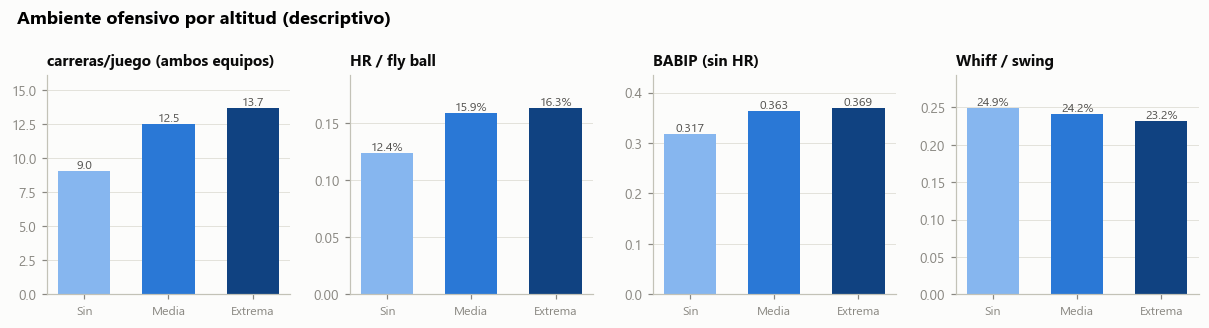

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(11, 3))
for ax, col, fmt in zip(axes, ["carreras/juego (ambos equipos)", "HR / fly ball", "BABIP (sin HR)", "Whiff / swing"],
                        ["{:.1f}", "{:.1%}", "{:.3f}", "{:.1%}"]):
    vals = env[col].reindex(ALTITUDE_ORDER)
    ax.bar(range(3), vals, color=[ALT_COLORS[c] for c in ALTITUDE_ORDER], width=0.62)
    for i, v in enumerate(vals):
        ax.text(i, v, fmt.format(v), ha="center", va="bottom", fontsize=8, color=INK2)
    ax.set_xticks(range(3)); ax.set_xticklabels(["Sin", "Media", "Extrema"], fontsize=8)
    ax.set_title(col, fontsize=10); ax.grid(axis="x", visible=False)
    ax.set_ylim(0, vals.max() * 1.18)
fig.suptitle("Ambiente ofensivo por altitud (descriptivo)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
savefig(fig, "02_ambiente_ofensivo"); plt.show()

## Resumen para el equipo
- La densidad del aire se puede **medir** por juego con el arrastre; separa claramente los 3 ambientes.
- Reconstruimos **~20 parques** con alta pureza; dentro de "Extreme" hay parques con densidades distintas.
- **Dos parques** (los de aire más delgado) son candidatos a Harp Helú → confirmar con ISAC.
- Para el modelo: usar `air_density_ratio` (continuo) y/o `park_id` en lugar de solo `altitude_category`.